# Fully-quantum covariance-adaptive random walk

Quantum version of the CLT covariance estimator in `FINAL.ipynb`, wired into the random-walk layout of
`qapthtdrjmcmc.ipynb`: parameter registers `A, f, t, tau, phi`, a `Walk` coin per parameter, and one
sub-circuit appended per timestep. The whole multi-timestep circuit is coherent. The only measurements
are the final read-out, and nothing is ever reset.

Following Tian, Lee & Zhou's adaptive scheme, the walk runs in two phases:

| phase | steps | proposal covariance |
|---|---|---|
| 1, conventional | `t_1` | `diag(v_p^2)` (the RW notebook's ±velocity walk); the state is copied into a history register after every step |
| 2, adaptive | `t_2` | `scale2 * S_hist + iso_var * I`, where `S_hist` is the sample covariance of the history registers in the **same branch** |

### From FINAL.ipynb to a circuit

`FINAL.ipynb` estimates `Σ`, takes a square root `L` (eigendecomposition), and draws `ε = L z` with
`z = Σ_k s_k / √n_rounds` (Rademacher signs, so `z` is approximately Gaussian by the CLT). Running an
eigendecomposition in superposition is out of reach, but any matrix `B` with `B Bᵀ ∝ Σ` works as the
square root. For the sample covariance of `K` history snapshots `h_1 … h_K` there is one built from
differences of pairs:

$$\sum_{a<b} (h_a-h_b)(h_a-h_b)^\top = K(K-1)\,S_\text{hist}.$$

So the circuit draws

$$\varepsilon = \sum_{a<b} r_{ab}\,(h_a-h_b),\qquad r_{ab}\in\{-1,0,+1\}\ \text{w.p.}\ \{q/2,\,1-q,\,q/2\},\quad q=\frac{\text{scale2}}{K(K-1)},$$

which gives `E[ε | h] = 0` and `Cov[ε | h] = scale2 · S_hist` **exactly**. This needs:

* **no mean and no division in superposition**: pair differences are automatically centred;
* **no fixed-point scaling**: the scale enters through an `RY` angle (`P(move) = q`), not through arithmetic;
* **no covariance matrix and no square root**: the covariance is estimated and applied in one step,
  and the CLT (a sum of independent symmetric terms) works over pairs where FINAL used `n_rounds`.

Gadgets per pair: `CSWAP(sign; h_a, h_b)` picks the orientation, two `move`-controlled reversible adders
apply `P += h_a − h_b`, and a second `CSWAP` restores the history. History snapshots are CNOT copies
into fresh registers. Every coin is a **fresh** qubit. By the deferred-measurement principle that is
equivalent to measuring and resetting a coin, without doing either (§2 shows why a reused coin cannot work).

**Periodic grid.** The parameter registers wrap mod `2^n`, like the modular shift in the RW notebook.
`P += h_a − h_b (mod 2^n)` is then the minimal-image move on the torus, so `S_hist` means the pairwise
minimal-image covariance (`torus_cov`). It equals `np.cov` whenever the history does not straddle the wrap.

In [1]:
import itertools
from collections import Counter

import numpy as np
from matplotlib import pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, AncillaRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator

## 1. Building blocks

The code below has three parts.

* **Reversible arithmetic**: only `X`/`MCX`/`CSWAP`, exact and ancilla-free.
* **Walk primitives and timestep sub-circuits**: the same role as `qc_timestep` in the RW notebook.
* **An exact simulator for this circuit class.** Each `h`/`ry` hits a fresh qubit that is only ever used as a
  control afterwards, so branches never interfere. The output distribution is then that of a reversible
  classical circuit driven by independent coin bits. `sample_circuit` / `exact_distribution` evaluate the
  *same* `QuantumCircuit` object that way, at sizes far beyond statevector memory (100+ qubits).
  They refuse any circuit outside that class, and §3–§4 check them against Aer's statevector simulator.

In [2]:
import itertools

import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, AncillaRegister, ClassicalRegister
from qiskit.circuit import ControlledGate


# =============================================================================
# 1. Reversible integer arithmetic (X / MCX / CSWAP only -> exact, ancilla-free)
#    Registers are little-endian (reg[0] = LSB), values are taken mod 2^len(reg).
# =============================================================================

def _mcx(qc, controls, target):
    if controls:
        qc.mcx(list(controls), target)
    else:
        qc.x(target)


def increment(qc, reg, ctrls=()):
    """reg <- reg + 1 (mod 2^len(reg)), controlled on every qubit in `ctrls`."""
    for j in reversed(range(len(reg))):
        _mcx(qc, list(ctrls) + list(reg[:j]), reg[j])


def decrement(qc, reg, ctrls=()):
    """reg <- reg - 1 (mod 2^len(reg)); the exact inverse of increment()."""
    for j in range(len(reg)):
        _mcx(qc, list(ctrls) + list(reg[:j]), reg[j])


def add_const(qc, reg, k, ctrls=()):
    """reg <- reg + k (mod 2^len(reg)); k may be negative."""
    k %= 2 ** len(reg)
    for i in range(len(reg)):
        if (k >> i) & 1:
            increment(qc, reg[i:], ctrls)


def add_reg(qc, src, dst, ctrls=(), sign=+1):
    """dst <- dst + sign*src (mod 2^len(dst)); src is untouched (it is only a control)."""
    step = increment if sign > 0 else decrement
    for i in range(min(len(src), len(dst))):
        step(qc, dst[i:], list(ctrls) + [src[i]])


# =============================================================================
# 2. Coins and walk primitives
# =============================================================================

def lazy_coin(qc, q_move, move, sign):
    """Fresh three-point coin r in {-1, 0, +1} with P(r = +-1) = q_move / 2.

    move = 1 w.p. q_move (RY), sign uniform (H). Both qubits must be fresh |0>.
    """
    if np.isclose(q_move, 1.0):
        qc.x(move)
    else:
        qc.ry(2 * np.arcsin(np.sqrt(q_move)), move)
    qc.h(sign)


def iso_step(qc, targets, velocity_list, signs, moves=None):
    """Independent +-v_p shift on each parameter (identity-covariance proposal).

    sign = 0 -> +v, sign = 1 -> -v; only applied when move = 1 (if `moves` given).
    `targets` is a list of register-lists that all receive the same shift.
    """
    for regs in targets:
        for p, (reg, v) in enumerate(zip(regs, velocity_list)):
            base = [] if moves is None else [moves[p]]
            add_const(qc, reg, +v, base)
            add_const(qc, reg, -2 * v, base + [signs[p]])


def snapshot(qc, P, H):
    """H <- P by CNOT fan-out. H must be fresh |0...0> (no cloning issue in the basis)."""
    for reg, hreg in zip(P, H):
        for q, h in zip(reg, hreg):
            qc.cx(q, h)


def add_signed(qc, t, dst, ctrls=(), sign=+1):
    """dst <- dst + sign * signed(t), reading the n-bit register t as two's complement."""
    n = len(t)
    up, down = (increment, decrement) if sign > 0 else (decrement, increment)
    for i in range(n - 1):
        up(qc, dst[i:], list(ctrls) + [t[i]])
    down(qc, dst[n - 1:], list(ctrls) + [t[n - 1]])


def pair_kick(qc, targets, Ha, Hb, move, sign, periodic=False, tmp=None):
    """target <- target + move * (+-)(Ha - Hb); the history registers are restored.

    Targets as wide as the history registers (the state P) are updated mod 2^n, which is
    exact on the periodic grid. Wider targets (e.g. an unwrapped displacement tracker)
    receive either the raw integer difference (periodic=False) or the minimal-image
    difference signed((Ha - Hb) mod 2^n) (periodic=True). The latter is computed in the
    clean scratch register `tmp` and uncomputed afterwards (tmp ends in |0>: no reset).
    """
    wide_periodic = []
    for ra, rb in zip(Ha, Hb):
        for qa, qb in zip(ra, rb):
            qc.cswap(sign, qa, qb)          # sign = 1 swaps the orientation of the pair
    for regs in targets:
        for reg, ra, rb in zip(regs, Ha, Hb):
            if periodic and len(reg) > len(ra):
                wide_periodic.append((reg, ra, rb))
                continue
            add_reg(qc, ra, reg, [move], +1)
            add_reg(qc, rb, reg, [move], -1)
    for ra, rb in zip(Ha, Hb):
        for qa, qb in zip(ra, rb):
            qc.cswap(sign, qa, qb)          # uncompute the swap

    # minimal-image targets: the sign is applied arithmetically (a swap would break the
    # +-2^(n-1) tie symmetry, because signed(a-b) = signed(b-a) = -2^(n-1) there)
    for reg, ra, rb in wide_periodic:
        if tmp is None:
            raise ValueError("periodic=True with a wider target needs a scratch register `tmp`")
        t = tmp[: len(ra)]
        add_reg(qc, ra, t, (), +1)                      # t = (a - b) mod 2^n
        add_reg(qc, rb, t, (), -1)
        add_signed(qc, t, reg, [move], +1)              # reg += signed(t)
        add_signed(qc, t, reg[1:], [move, sign], -1)    # reg -= 2 signed(t) if sign = 1
        add_reg(qc, rb, t, (), +1)                      # uncompute t -> |0>
        add_reg(qc, ra, t, (), -1)


def history_pairs(K):
    return list(itertools.combinations(range(K), 2))


def kick_probability(K, scale2, n_rounds=1):
    q = scale2 / (K * (K - 1) * n_rounds)
    if not 0 < q <= 1:
        raise ValueError(
            f"q = scale2 / (K (K-1) n_rounds) = {q:.3f} must be in (0, 1]: "
            "lower scale2 or raise K / n_rounds"
        )
    return q


def covariance_kick(qc, targets, history, coins, scale2, n_rounds=1, periodic=False, tmp=None):
    """Coherent proposal  eps = sum_{rounds} sum_{a<b} r_ab (h_a - h_b).

    With r_ab in {-1, 0, +1} w.p. {q/2, 1-q, q/2} and q = scale2 / (K (K-1) n_rounds):
        E[eps | h] = 0,   Cov[eps | h] = scale2 * S_hist   (unbiased sample covariance)
    because  sum_{a<b} (h_a - h_b)(h_a - h_b)^T = K (K-1) S_hist.
    On the periodic grid the differences are minimal-image ones (see torus_cov()).
    `coins` yields one fresh (move, sign) qubit pair per (round, pair).
    """
    K = len(history)
    q = kick_probability(K, scale2, n_rounds)
    coins = iter(coins)
    for _ in range(n_rounds):
        for a, b in history_pairs(K):
            move, sign = next(coins)
            lazy_coin(qc, q, move, sign)
            pair_kick(qc, targets, history[a], history[b], move, sign, periodic, tmp)
    return q


# =============================================================================
# 3. Timestep sub-circuits (same layout as qc_timestep in qapthtdrjmcmc.ipynb)
# =============================================================================

def conventional_timestep(P, velocity_list, t, extra_targets=()):
    """Phase-1 step: independent +-v_p on every parameter, one FRESH coin per parameter."""
    coin = AncillaRegister(len(P), f"Walk{t}")
    extra = [r for regs in extra_targets for r in regs]
    step = QuantumCircuit(*P, *extra, coin, name=f"Walk{t}")
    step.h(coin)
    iso_step(step, [P, *extra_targets], velocity_list, coin)
    return step


def adaptive_timestep(P, H, t, scale2, iso_var, n_rounds=1, extra_targets=(), tmp=None):
    """Phase-2 step: covariance kick from the history registers + identity term.

    Cov[step | history] = scale2 * S_hist + iso_var * I   (grid units).
    """
    K, d = len(H), len(P)
    n_coins = n_rounds * K * (K - 1) // 2
    move = AncillaRegister(n_coins, f"Move{t}")
    sign = AncillaRegister(n_coins, f"Sign{t}")
    coin_regs = [move, sign]
    if iso_var > 0:
        imove = AncillaRegister(d, f"IsoMove{t}")
        isign = AncillaRegister(d, f"IsoSign{t}")
        coin_regs += [imove, isign]
    extra = [r for regs in extra_targets for r in regs]
    hist = [r for h in H for r in h]
    work = [tmp] if tmp is not None else []
    step = QuantumCircuit(*P, *extra, *hist, *work, *coin_regs, name=f"AdaptiveWalk{t}")
    targets = [P, *extra_targets]
    covariance_kick(step, targets, H, zip(move, sign), scale2, n_rounds, True, tmp)
    if iso_var > 0:
        for p in range(d):
            lazy_coin(step, iso_var, imove[p], isign[p])
        iso_step(step, targets, [1] * d, isign, imove)
    return step


def snapshot_step(P, H, k):
    step = QuantumCircuit(*P, *H, name=f"Snapshot{k}")
    snapshot(step, P, H)
    return step


def build_adaptive_walk(
    params,
    n_bits_list,
    velocity_list,
    t_1,
    t_2,
    scale2=None,
    iso_var=0.1,
    n_rounds=1,
    initial_values=None,
    include_initial=False,
    track_displacement=False,
    e_bits=8,
    record_path=False,
    measure=True,
):
    """Full fully-coherent adaptive walk: t_1 conventional steps (recording history),
    then t_2 adaptive steps whose covariance is the history covariance (+ iso_var * I).
    No measurement or reset anywhere before the final read-out.

    record_path=True also copies the state into a fresh record register after every
    adaptive step (for plotting the walk). Records are never read by the walk itself.
    """
    d = len(params)
    if scale2 is None:
        scale2 = 2.38 ** 2 / d                         # Haario / Gelman-Roberts-Gilks
    n_snap = t_1 + int(include_initial)
    q = kick_probability(n_snap, scale2, n_rounds)     # fail fast on an invalid scale
    for p, n, v in zip(params, n_bits_list, velocity_list):
        if (2 * v) % 2 ** n == 0:
            raise ValueError(f"{p}: +{v} and -{v} coincide mod {2**n}; the walk would be deterministic")
    P = [QuantumRegister(n, p) for p, n in zip(params, n_bits_list)]
    H = [[QuantumRegister(n, f"{p}_h{k}") for p, n in zip(params, n_bits_list)]
         for k in range(n_snap)]
    Dreg = [QuantumRegister(e_bits, f"{p}_disp") for p in params] if track_displacement else []
    extra = [Dreg] if track_displacement else []
    tmp = AncillaRegister(max(n_bits_list), "diff_tmp") if track_displacement else None

    qc = QuantumCircuit(*P, *Dreg, *[r for h in H for r in h], *([tmp] if tmp is not None else []))

    # initial basis state (X gates instead of initialize(), which contains a reset)
    for reg, val in zip(P, initial_values or [0] * d):
        for i in range(len(reg)):
            if (val >> i) & 1:
                qc.x(reg[i])
    qc.barrier()

    k = 0
    if include_initial:
        snap = snapshot_step(P, H[k], k)
        qc.append(snap, snap.qubits)
        k += 1

    # ---- phase 1: conventional walk, record the state history ---------------------
    for t in range(t_1):
        step = conventional_timestep(P, velocity_list, t)
        qc.add_register(*step.qregs[d:])
        qc.append(step, step.qubits)
        snap = snapshot_step(P, H[k], k)
        qc.append(snap, snap.qubits)
        k += 1
    qc.barrier()

    # ---- phase 2: adaptive walk, step covariance = scale2 * S_hist + iso_var * I ---
    R = []
    for t in range(t_1, t_1 + t_2):
        step = adaptive_timestep(P, H, t, scale2, iso_var, n_rounds, extra_targets=extra, tmp=tmp)
        n_own = d + len(Dreg) + len(H) * d + int(tmp is not None)
        qc.add_register(*step.qregs[n_own:])
        qc.append(step, step.qubits)
        if record_path:
            rec = [QuantumRegister(n, f"{p}_r{t}") for p, n in zip(params, n_bits_list)]
            qc.add_register(*rec)
            snap = snapshot_step(P, rec, t)
            snap.name = f"Record{t}"
            qc.append(snap, snap.qubits)
            R.append(rec)

    if measure:
        qc.barrier()
        creg_P = ClassicalRegister(sum(n_bits_list), "c_state")
        qc.add_register(creg_P)
        qc.measure(sum(map(list, P), []), creg_P)
        for kk, h in enumerate(H):
            c = ClassicalRegister(sum(n_bits_list), f"c_h{kk}")
            qc.add_register(c)
            qc.measure(sum(map(list, h), []), c)
        for t, rec in zip(range(t_1, t_1 + t_2), R):
            c = ClassicalRegister(sum(n_bits_list), f"c_r{t}")
            qc.add_register(c)
            qc.measure(sum(map(list, rec), []), c)
        if track_displacement:
            c = ClassicalRegister(d * e_bits, "c_disp")
            qc.add_register(c)
            qc.measure(sum(map(list, Dreg), []), c)

    regs = dict(P=P, H=H, D=Dreg, R=R, tmp=tmp, q=q, scale2=scale2, iso_var=iso_var)
    return qc, regs


# =============================================================================
# 4. Exact simulation for "fresh coins + reversible gates" circuits
# =============================================================================
#
# Every h / ry in these circuits hits a fresh |0> qubit that is only ever used as a
# control afterwards, so no branch ever interferes with another and (deferred
# measurement principle) the output distribution equals that of a classical
# reversible circuit driven by independent coin bits. This lets us evaluate the
# exact same QuantumCircuit object at sizes far beyond statevector memory. It is
# cross-checked against Aer's statevector simulator below.

_PERM_GATES = {"x", "cx", "ccx", "mcx", "cswap", "swap"}
_COIN_GATES = {"h", "ry"}
_SKIP = {"barrier", "measure"}


def _flat_ops(qc, qmap=None):
    """Yield (name, operation, [global qubit indices]) with composite blocks inlined."""
    if qmap is None:
        qmap = {q: i for i, q in enumerate(qc.qubits)}
    for inst in qc.data:
        op = inst.operation
        qs = [qmap[q] for q in inst.qubits]
        if isinstance(op, ControlledGate) and op.base_gate.name == "x":
            if op.ctrl_state != 2 ** op.num_ctrl_qubits - 1:
                raise ValueError("open-controlled X not supported by the sampler")
            yield "mcx", op, qs                 # cx, ccx, C3X, C4X, MCXGrayCode, ...
        elif op.name in _PERM_GATES | _COIN_GATES | _SKIP | {"reset", "initialize"}:
            yield op.name, op, qs
        elif op.definition is not None:
            inner = op.definition
            yield from _flat_ops(inner, {iq: qs[i] for i, iq in enumerate(inner.qubits)})
        else:
            raise ValueError(f"cannot inline gate {op.name}")


def check_coherent(qc):
    """Assert there is no reset and no gate acting on a qubit after it was measured."""
    measured = set()
    n_meas = 0
    for name, _, qs in _flat_ops(qc):
        if name in ("reset", "initialize"):
            raise AssertionError(f"found {name}: not allowed")
        if name == "measure":
            measured.update(qs)
            n_meas += 1
        elif name != "barrier" and measured.intersection(qs):
            raise AssertionError(f"{name} acts on an already-measured qubit")
    return n_meas


def _coin_list(qc):
    coins = []
    for name, op, qs in _flat_ops(qc):
        if name in _COIN_GATES:
            p1 = 0.5 if name == "h" else float(np.sin(float(op.params[0]) / 2) ** 2)
            coins.append((qs[0], p1))
    return coins


def _run_reversible(qc, coin_columns, n_rows, init=None):
    """Propagate basis states; coin_columns[j] gives the bits of the j-th coin gate.
    `init` (num_qubits, n_rows) optionally sets the input basis states (default |0...0>)."""
    nq = qc.num_qubits
    bits = np.zeros((nq, n_rows), dtype=bool) if init is None else np.array(init, dtype=bool)
    fresh = np.ones(nq, dtype=bool)
    is_coin = np.zeros(nq, dtype=bool)
    j = 0
    for name, op, qs in _flat_ops(qc):
        if name in _SKIP:
            continue
        if name in _COIN_GATES:
            (t,) = qs
            if not fresh[t]:
                raise ValueError(f"{name} on non-fresh qubit {t}: interference possible")
            bits[t] = coin_columns[j]
            j += 1
            fresh[t] = False
            is_coin[t] = True
            continue
        if name in ("x", "cx", "ccx", "mcx"):
            *c, t = qs
            if is_coin[t]:
                raise ValueError("a coin is used as a target")
            if c:
                m = bits[c[0]].copy()
                for ci in c[1:]:
                    m &= bits[ci]
                bits[t] ^= m
            else:
                bits[t] ^= True
            fresh[t] = False
            continue
        if name in ("cswap", "swap"):
            if name == "cswap":
                c, a, b = qs
                diff = (bits[a] ^ bits[b]) & bits[c]
            else:
                a, b = qs
                diff = bits[a] ^ bits[b]
            if is_coin[a] or is_coin[b]:
                raise ValueError("a coin is swapped")
            bits[a] ^= diff
            bits[b] ^= diff
            fresh[a] = fresh[b] = False
            continue
        raise ValueError(f"unsupported gate {name}")
    return bits


def sample_circuit(qc, shots, seed=None):
    """Exact sampling of the circuit's final computational-basis state.
    Returns a bool array of shape (num_qubits, shots)."""
    rng = np.random.default_rng(seed)
    cols = [rng.random(shots) < p1 for _, p1 in _coin_list(qc)]
    return _run_reversible(qc, cols, shots)


def exact_distribution(qc, max_coins=22):
    """Exact output distribution by enumerating every coin outcome.
    Returns (bits of shape (num_qubits, rows), probabilities of shape (rows,))."""
    coins = _coin_list(qc)
    nc = len(coins)
    if nc > max_coins:
        raise ValueError(f"{nc} coins: too many to enumerate, use sample_circuit()")
    grid = ((np.arange(2 ** nc)[None, :] >> np.arange(nc)[:, None]) & 1).astype(bool)
    w = np.ones(2 ** nc)
    for j, (_, p1) in enumerate(coins):
        w *= np.where(grid[j], p1, 1 - p1)
    keep = w > 0
    return _run_reversible(qc, list(grid[:, keep]), int(keep.sum())), w[keep]


def reg_value(bits, qc, reg, signed=False):
    """Integer value of a register from a (num_qubits, rows) bit array."""
    cols = [qc.find_bit(q).index for q in reg]
    v = (bits[cols].astype(np.int64) * (1 << np.arange(len(cols)))[:, None]).sum(0)
    if signed:
        v = np.where(v >= 2 ** (len(cols) - 1), v - 2 ** len(cols), v)
    return v


def regs_values(bits, qc, regs, signed=False):
    """(rows, len(regs)) array of register values."""
    return np.stack([reg_value(bits, qc, r, signed) for r in regs], axis=1)


def weighted_cov(X, w=None):
    """Covariance of rows of X under probability weights w (population form)."""
    if w is None:
        w = np.full(len(X), 1 / len(X))
    w = w / w.sum()
    mu = w @ X
    Xc = X - mu
    return Xc.T @ (Xc * w[:, None]), mu


def torus_cov(hist, n_bits):
    """Pairwise (minimal-image) sample covariance of K snapshots on a periodic 2^n grid.

    hist: (..., K, d) integer array. Equals np.cov(..., ddof=1) whenever the snapshots
    do not straddle the wrap-around; it is always PSD (a sum of outer products).
    """
    K = hist.shape[-2]
    S = 0
    for a, b in history_pairs(K):
        dlt = (hist[..., a, :] - hist[..., b, :]) % 2 ** n_bits
        dlt = np.where(dlt >= 2 ** (n_bits - 1), dlt - 2 ** n_bits, dlt)
        S = S + dlt[..., :, None] * dlt[..., None, :]
    return S / (K * (K - 1))


def cov_metrics(A, B, eps=1e-12):
    """The three metrics used in FINAL.ipynb (A = estimate, B = target)."""
    den = np.linalg.norm(A, "fro") * np.linalg.norm(B, "fro")
    return dict(
        hs_similarity=np.vdot(A, B).real / den if den > eps else np.nan,
        relative_error=np.linalg.norm(A - B, "fro") / max(np.linalg.norm(B, "fro"), eps),
        frobenius_distance=np.linalg.norm(A - B, "fro"),
    )

Exhaustive check: every gadget is the intended permutation on every basis input.

In [3]:
def permutation_of(qc):
    U = Operator(qc).data
    assert np.allclose(np.abs(U), np.round(np.abs(U))), "not a permutation matrix"
    return np.argmax(np.abs(U), axis=0)            # basis index j -> image index


def bits_to_int(vals_widths):
    out, off = 0, 0
    for v, w in vals_widths:
        out |= (v % 2**w) << off
        off += w
    return out


mismatches = 0
for n in (1, 2, 3):
    # controlled add_const, add_reg (both signs, unequal widths)
    for k in range(-5, 6):
        r, c = QuantumRegister(n), QuantumRegister(1)
        qc = QuantumCircuit(r, c); add_const(qc, r, k, [c[0]])
        pm = permutation_of(qc)
        for x, cv in itertools.product(range(2**n), (0, 1)):
            mismatches += pm[bits_to_int([(x, n), (cv, 1)])] != bits_to_int([(x + k*cv, n), (cv, 1)])
    for ns, sgn in itertools.product((max(1, n-1), n, n+1), (+1, -1)):
        a, b, c = QuantumRegister(ns), QuantumRegister(n), QuantumRegister(1)
        qc = QuantumCircuit(a, b, c); add_reg(qc, a, b, [c[0]], sgn)
        pm = permutation_of(qc)
        for av, bv, cv in itertools.product(range(2**ns), range(2**n), (0, 1)):
            mismatches += pm[bits_to_int([(av, ns), (bv, n), (cv, 1)])] != \
                          bits_to_int([(av, ns), (bv + sgn*cv*av, n), (cv, 1)])

# periodic pair kick into a wider register: dst += move * (+-) minimal_image(ha - hb), tmp returns to 0.
# Includes the tie (ha - hb = 2^(n-1)), whose kick must still be symmetric. Too wide for Operator(),
# so all basis inputs are pushed through the reversible-gate evaluator instead.
def encode(cols, widths):
    return np.concatenate([((c[:, None] >> np.arange(w)) & 1).T for c, w in zip(cols, widths)]).astype(bool)

for n, e in [(2, 4), (3, 5), (3, 7)]:
    ha, hb, dst, tmp = QuantumRegister(n, "ha"), QuantumRegister(n, "hb"), QuantumRegister(e, "dst"), QuantumRegister(n, "tmp")
    mv, sg = QuantumRegister(1, "mv"), QuantumRegister(1, "sg")
    qc = QuantumCircuit(ha, hb, dst, tmp, mv, sg)
    pair_kick(qc, [[dst]], [ha], [hb], mv[0], sg[0], periodic=True, tmp=tmp)
    a_, b_, d_, m_, s_ = np.array(list(itertools.product(range(2**n), range(2**n), range(2**e), (0, 1), (0, 1)))).T
    zero = np.zeros_like(a_)
    diff = (a_ - b_) % 2**n
    diff = np.where(diff >= 2**(n-1), diff - 2**n, diff)                 # minimal image
    widths = [n, n, e, n, 1, 1]
    out = _run_reversible(qc, [], len(a_), init=encode([a_, b_, d_, zero, m_, s_], widths))
    exp = encode([a_, b_, (d_ + m_ * (1 - 2*s_) * diff) % 2**e, zero, m_, s_], widths)
    mismatches += int(np.any(out != exp, axis=0).sum())

print("gadget mismatches over all basis inputs:", mismatches)
assert mismatches == 0

gadget mismatches over all basis inputs: 0


## 2. Why every timestep needs fresh coins

`qapthtdrjmcmc.ipynb` applies `H · (controlled ±v shift) · H` to the same `Walk` coin at every timestep.
Between two steps the coin sees `H·H = I`, so the coin is never re-randomised. The walker then moves
**ballistically**: after `T` steps it sits at `±T·v`, with nothing in between. The cell below rebuilds that
operator verbatim (one parameter, `v = 1`, resolution 8 so `±v` are distinct) and compares it with the
same walk using a fresh coin per step. The fresh-coin walk gives the binomial / CLT spread that MCMC needs.

There is a second issue in that notebook's settings: `resolution 4` with `velocity 2` makes `+2 ≡ −2 (mod 4)`,
so four of the five parameters move deterministically. `build_adaptive_walk` now raises an error for that case.

In [4]:
nb_demo, v_demo = 3, 1
D_demo = 2**nb_demo

# --- verbatim RW-notebook operator: H . (ctrl-0 M, ctrl-1 M^dag) . H, coin reused -------------
M = np.zeros((D_demo, D_demo))
for i in range(D_demo):
    M[i][(i + v_demo) % D_demo] = 1
x_reg, c_reg = QuantumRegister(nb_demo, "A"), AncillaRegister(1, "Walk")
rw_step = QuantumCircuit(x_reg, c_reg, name="Walk")
rw_step.h(c_reg)
rw_step.append(UnitaryGate(M).control(1, ctrl_state=0), [c_reg[0], *x_reg])
rw_step.append(UnitaryGate(M.conj().T).control(1, ctrl_state=1), [c_reg[0], *x_reg])
rw_step.h(c_reg)

def centred(p):                       # distribution over displacement -D/2 .. D/2-1
    return {((k + D_demo//2) % D_demo) - D_demo//2: round(float(v), 3) for k, v in enumerate(p) if v > 1e-9}

for T in (1, 2, 3, 4):
    qc_reused = QuantumCircuit(x_reg, c_reg)
    for _ in range(T):
        qc_reused.append(rw_step, [*x_reg, c_reg[0]])
    p_reused = Statevector(qc_reused).probabilities(list(range(nb_demo)))

    coins = AncillaRegister(T, "Walk")
    qc_fresh = QuantumCircuit(x_reg, coins)
    for t in range(T):
        qc_fresh.h(coins[t])
        iso_step(qc_fresh, [[x_reg]], [v_demo], [coins[t]])
    p_fresh = Statevector(qc_fresh).probabilities(list(range(nb_demo)))

    print(f"T={T}  reused coin: {centred(p_reused)}")
    print(f"      fresh coins: {centred(p_fresh)}")

T=1  reused coin: {1: 0.5, -1: 0.5}
      fresh coins: {1: 0.5, -1: 0.5}


T=2  reused coin: {2: 0.5, -2: 0.5}
      fresh coins: {0: 0.5, 2: 0.25, -2: 0.25}


T=3  reused coin: {3: 0.5, -3: 0.5}
      fresh coins: {1: 0.375, 3: 0.125, -3: 0.125, -1: 0.375}


T=4  reused coin: {-4: 1.0}
      fresh coins: {0: 0.375, 2: 0.25, -4: 0.125, -2: 0.25}


## 3. Quantum covariance estimation (the `FINAL.ipynb` test, coherently)

This mirrors `FINAL.ipynb`. Draw a few correlated parameter snapshots, compute the target covariance
classically, then let the circuit generate `ε`. The snapshots are loaded into history registers with `X`
gates; in §4 they come from the walk itself. `ε` goes into a wide signed register, so nothing wraps.
Following FINAL, the result is scored with the HS similarity, relative Frobenius error and Frobenius
distance: once exactly, and once from 4096 shots (FINAL used 64 wavelets).

Unlike FINAL, the target is `scale2 · S_hist` with no trace normalisation. The step covariance is
*proportional* to the history covariance, as in Haario's adaptive Metropolis, and `scale2 = 2.38²/d`.
FINAL also used `C Cᵀ` from a cross-covariance. That squares the eigenvalues, so it changes the shape of
the step distribution and is not the history covariance. Any linear random combination of the data has a
covariance of the form `Σ d dᵀ`, so `C Cᵀ` would need coherent multiplication on top.

In [5]:
params = ["A", "f", "t", "tau", "phi"]
N_params = len(params)

n_bits_hist = 3          # 8-point grid per parameter
K = 5                    # history snapshots (FINAL used 64 wavelets)
e_bits = 8               # signed output register, wide enough that nothing wraps
scale2 = 2.38**2 / N_params

rng = np.random.default_rng(0)
L_true = np.array([[1.0, 0, 0, 0, 0],
                   [0.8, 0.6, 0, 0, 0],
                   [0, 0, 1.0, 0, 0],
                   [0, 0, -0.7, 0.7, 0],
                   [0.3, 0, 0, 0, 0.9]])
history = np.clip(np.round(3.5 + 1.4 * (L_true @ rng.normal(size=(N_params, K)))), 0, 2**n_bits_hist - 1).astype(int)

S_hist = np.cov(history, ddof=1)
Sigma_target = scale2 * S_hist
print("history (params x snapshots):\n", history)
print("\nTarget covariance  scale2 * S_hist:\n", Sigma_target.round(3))

history (params x snapshots):
 [[4 3 4 4 3]
 [4 4 5 3 2]
 [3 4 0 3 2]
 [3 3 5 4 6]
 [3 5 3 4 4]]

Target covariance  scale2 * S_hist:
 [[ 0.34   0.34  -0.34  -0.17  -0.397]
 [ 0.34   1.473 -0.623 -0.736 -0.397]
 [-0.34  -0.623  2.606 -1.529  0.963]
 [-0.17  -0.736 -1.529  1.926 -0.227]
 [-0.397 -0.397  0.963 -0.227  0.793]]


In [6]:
H_regs = [[QuantumRegister(n_bits_hist, f"{p}_h{k}") for p in params] for k in range(K)]
E_regs = [QuantumRegister(e_bits, f"{p}_eps") for p in params]
n_pairs = K * (K - 1) // 2
move_reg, sign_reg = AncillaRegister(n_pairs, "move"), AncillaRegister(n_pairs, "sign")

qc_cov = QuantumCircuit(*E_regs, *[r for h in H_regs for r in h], move_reg, sign_reg)
for k in range(K):                                   # load the snapshots (basis states)
    for p in range(N_params):
        for i in range(n_bits_hist):
            if (history[p, k] >> i) & 1:
                qc_cov.x(H_regs[k][p][i])
q_cov = covariance_kick(qc_cov, [E_regs], H_regs, zip(move_reg, sign_reg), scale2)
print(f"qubits = {qc_cov.num_qubits}, gates = {len(qc_cov.data)}, q = P(move) = {q_cov:.4f}")

# exact output distribution of the circuit (2^20 coin outcomes)
bits, w = exact_distribution(qc_cov)
eps = regs_values(bits, qc_cov, E_regs, signed=True)
cov_exact, mean_exact = weighted_cov(eps, w)
print("\nexact mean of eps:", mean_exact.round(12))
print("exact Cov(eps):\n", cov_exact.round(3))
print("metrics (exact):", {k: float(f"{v:.3e}") for k, v in cov_metrics(cov_exact, Sigma_target).items()})
print("history registers restored:",
      all(np.all(reg_value(bits, qc_cov, H_regs[k][p]) == history[p, k]) for k in range(K) for p in range(N_params)))

# finite shots, as in FINAL's empirical check
shot_bits = sample_circuit(qc_cov, 4096, seed=1)
eps_shots = regs_values(shot_bits, qc_cov, E_regs, signed=True)
print("metrics (4096 shots):", {k: round(float(v), 4) for k, v in cov_metrics(np.cov(eps_shots.T), Sigma_target).items()})

m2 = w @ eps**2
m4 = w @ eps**4
print("\nexcess kurtosis per parameter (0 for a Gaussian):", (m4 / m2**2 - 3).round(2))

qubits = 135, gates = 2457, q = P(move) = 0.0566



exact mean of eps: [-0.  0. -0.  0. -0.]
exact Cov(eps):
 [[ 0.34   0.34  -0.34  -0.17  -0.397]
 [ 0.34   1.473 -0.623 -0.736 -0.397]
 [-0.34  -0.623  2.606 -1.529  0.963]
 [-0.17  -0.736 -1.529  1.926 -0.227]
 [-0.397 -0.397  0.963 -0.227  0.793]]
metrics (exact): {'hs_similarity': 1.0, 'relative_error': 1.568e-14, 'frobenius_distance': 7.529e-14}


history registers restored: True
metrics (4096 shots): {'hs_similarity': 0.9998, 'relative_error': 0.0346, 'frobenius_distance': 0.1662}

excess kurtosis per parameter (0 for a Gaussian): [2.44 2.9  3.14 2.71 2.84]


The covariance is exact (relative error ~1e-14). The remaining non-Gaussianity is the lattice
plus the lazy coin: with `P(move) = q`, a single pair contributes excess kurtosis `1/q − 3`, which is 0 at
`q = 1/3` (the 3-point Gauss–Hermite rule). Summing over pairs shrinks it, as the CLT predicts. Extra
FINAL-style rounds at `q/n_rounds` per round do not help on a lattice: excess kurtosis = `1/q − 3/n_rounds`.

**Coherence check against Aer.** Next, put the history itself in superposition over all
`4^6 = 4096` histories (a reduced instance: 2 parameters, 2-bit grid, `K = 3`, 3-bit output, 24 qubits).
Aer's statevector simulator then has to reproduce `uniform(history) × kick distribution` in every branch.

In [7]:
d_s, nb_s, K_s, eb_s, scale2_s = 2, 2, 3, 3, 1.5
H_s = [[QuantumRegister(nb_s, f"{p}_h{k}") for p in params[:d_s]] for k in range(K_s)]
E_s = [QuantumRegister(eb_s, f"{p}_eps") for p in params[:d_s]]
np_s = K_s * (K_s - 1) // 2
mv_s, sg_s = AncillaRegister(np_s, "move"), AncillaRegister(np_s, "sign")
qc_s = QuantumCircuit(*E_s, *[r for h in H_s for r in h], mv_s, sg_s)
for h in H_s:
    for r in h:
        qc_s.h(r)                                         # every history at once
q_s = covariance_kick(qc_s, [E_s], H_s, zip(mv_s, sg_s), scale2_s)

observed = [qc_s.find_bit(x).index for r in E_s + [r for h in H_s for r in h] for x in r]
qc_s_aer = qc_s.copy()
qc_s_aer.save_probabilities(observed)
sv_sim = AerSimulator(method="statevector")
p_aer = sv_sim.run(transpile(qc_s_aer, sv_sim)).result().data()["probabilities"]

p_ref = np.zeros_like(p_aer)                              # analytic, no circuit involved
pairs_s = history_pairs(K_s)
for hv in itertools.product(range(2**nb_s), repeat=d_s * K_s):
    hv = np.array(hv).reshape(K_s, d_s)
    for rs in itertools.product((-1, 0, 1), repeat=np_s):
        pr = np.prod([q_s / 2 if r else 1 - q_s for r in rs]) / 2**(nb_s * d_s * K_s)
        e = sum((r * (hv[a] - hv[b]) for r, (a, b) in zip(rs, pairs_s)), np.zeros(d_s, int))
        p_ref[bits_to_int([(int(x), eb_s) for x in e] + [(int(x), nb_s) for x in hv.ravel()])] += pr

print(f"{qc_s.num_qubits} qubits;  TV distance(Aer statevector, analytic) = {0.5 * np.abs(p_aer - p_ref).sum():.2e}")

24 qubits;  TV distance(Aer statevector, analytic) = 3.04e-16


## 4. Integration into the random walk (layout of `qapthtdrjmcmc.ipynb`)

The registers and settings follow the RW notebook. The grid is 16 points per parameter, because the RW
notebook's 4 points make `velocity 2` degenerate (§2). Each timestep is a named sub-circuit appended
to `qc`, like `qc_timestep`:

* `Walk{t}`: the conventional ±velocity step, with a fresh `Walk{t}` coin register per step;
* `Snapshot{k}`: CNOT copy of the state into history register `k`;
* `AdaptiveWalk{t}`: the covariance kick from all history pairs, plus the `iso_var · I` term
  (the "+ identity" regulariser in Tian–Lee–Zhou / Haario). It also keeps `S_hist` from collapsing
  when the history is degenerate.

The `*_disp` registers are an optional diagnostic. They receive every phase-2 kick in unwrapped,
minimal-image form, using a scratch register that is uncomputed (never reset), so the per-branch
covariance can be checked. `P` never depends on them.

In [8]:
params = ["A", "f", "t", "tau", "phi"]
N_params = len(params)
resolution_list = [16] * N_params          # must be powers of 2 (registers wrap mod 2^n)
velocity_list = [1, 2, 2, 2, 2]            # as in qapthtdrjmcmc.ipynb
n_bits_list = [int(np.log2(r)) for r in resolution_list]
assert all(2**n == r for n, r in zip(n_bits_list, resolution_list))

t_1 = 3                                    # conventional steps -> K = t_1 history snapshots
t_2 = 3                                    # adaptive steps
scale2 = 2.38**2 / N_params
iso_var = 0.1
initial_values = [0] * N_params            # same initial basis state as the RW notebook

qc, regs = build_adaptive_walk(
    params, n_bits_list, velocity_list, t_1, t_2,
    scale2=scale2, iso_var=iso_var, initial_values=initial_values,
    track_displacement=True, e_bits=8,
)

n_meas = check_coherent(qc)                # raises on any reset / gate after a measurement
ops = Counter(name for name, _, _ in _flat_ops(qc))
print(f"qubits: {qc.num_qubits}   kick probability q = {regs['q']:.4f}")
print(f"measurements: {n_meas}, all in the final read-out; resets: 0")
print("gate counts:", dict(ops))
print("top-level blocks:", [inst.operation.name for inst in qc.data if inst.operation.name not in ("barrier", "measure")])

qubits: 187   kick probability q = 0.1888
measurements: 120, all in the final read-out; resets: 0
gate counts: {'barrier': 3, 'h': 39, 'mcx': 5697, 'x': 15, 'ry': 24, 'cswap': 360, 'measure': 120}
top-level blocks: ['Walk0', 'Snapshot0', 'Walk1', 'Snapshot1', 'Walk2', 'Snapshot2', 'AdaptiveWalk3', 'AdaptiveWalk4', 'AdaptiveWalk5']


### Exact validation on a reduced instance

Two parameters on a 4-point grid, with `t_1 = 2`, `t_2 = 1` and `n_rounds = 2` (so that `q ≤ 1` with only one
history pair). That is 24 qubits, small enough for Aer's statevector simulator. Three independent routes
should agree:
1. Aer statevector on the circuit;
2. exact enumeration of the same circuit (`exact_distribution`);
3. a pure-NumPy model of the intended process, built without the circuit.

In [9]:
pr_small, nb_small, v_small = ["A", "f"], [2, 2], [1, 1]
qc_small, R_small = build_adaptive_walk(pr_small, nb_small, v_small, t_1=2, t_2=1,
                                        scale2=2.38**2 / 2, iso_var=0.25, n_rounds=2, measure=False)
obs_small = [qc_small.find_bit(x).index for r in R_small["P"] + [r for h in R_small["H"] for r in h] for x in r]

qa = qc_small.copy(); qa.save_probabilities(obs_small)
p_aer = sv_sim.run(transpile(qa, sv_sim)).result().data()["probabilities"]

bits_small, w_small = exact_distribution(qc_small)
idx = sum(bits_small[o].astype(np.int64) << j for j, o in enumerate(obs_small))
p_enum = np.bincount(idx, weights=w_small, minlength=len(p_aer))

# independent model: phase-1 signs, snapshots, then 2 rounds x 1 pair + identity term
Dg, qk, iso = 4, R_small["q"], R_small["iso_var"]
p_model = np.zeros_like(p_aer)
for s in itertools.product((1, -1), repeat=4):
    x, hs = np.zeros(2, int), []
    for t in range(2):
        x = (x + np.array(v_small) * np.array(s[2*t:2*t+2])) % Dg
        hs.append(x.copy())
    for rs in itertools.product((-1, 0, 1), repeat=2):
        for ri in itertools.product((-1, 0, 1), repeat=2):
            pr = np.prod([qk/2 if r else 1-qk for r in rs]) * np.prod([iso/2 if r else 1-iso for r in ri]) / 16
            xf = (x + sum(rs) * (hs[0] - hs[1]) + np.array(ri)) % Dg
            p_model[bits_to_int([(int(v), 2) for v in [*xf, *hs[0], *hs[1]]])] += pr

shots = 200_000
bits_sh = sample_circuit(qc_small, shots, seed=3)
idx = sum(bits_sh[o].astype(np.int64) << j for j, o in enumerate(obs_small))
p_shots = np.bincount(idx, minlength=len(p_aer)) / shots
tv_expected = 0.5 * np.sum(np.sqrt(2 * p_aer * (1 - p_aer) / (np.pi * shots)))

print(f"{qc_small.num_qubits} qubits, {np.count_nonzero(p_aer > 1e-12)} reachable outcomes")
print(f"TV(Aer, NumPy model)      = {0.5*np.abs(p_aer - p_model).sum():.2e}")
print(f"TV(Aer, exact enumeration) = {0.5*np.abs(p_aer - p_enum).sum():.2e}")
print(f"TV(Aer, {shots} sampled shots) = {0.5*np.abs(p_aer - p_shots).sum():.4f}   (shot-noise expectation {tv_expected:.4f})")

24 qubits, 256 reachable outcomes
TV(Aer, NumPy model)      = 2.21e-16
TV(Aer, exact enumeration) = 2.78e-16
TV(Aer, 200000 sampled shots) = 0.0136   (shot-noise expectation 0.0129)


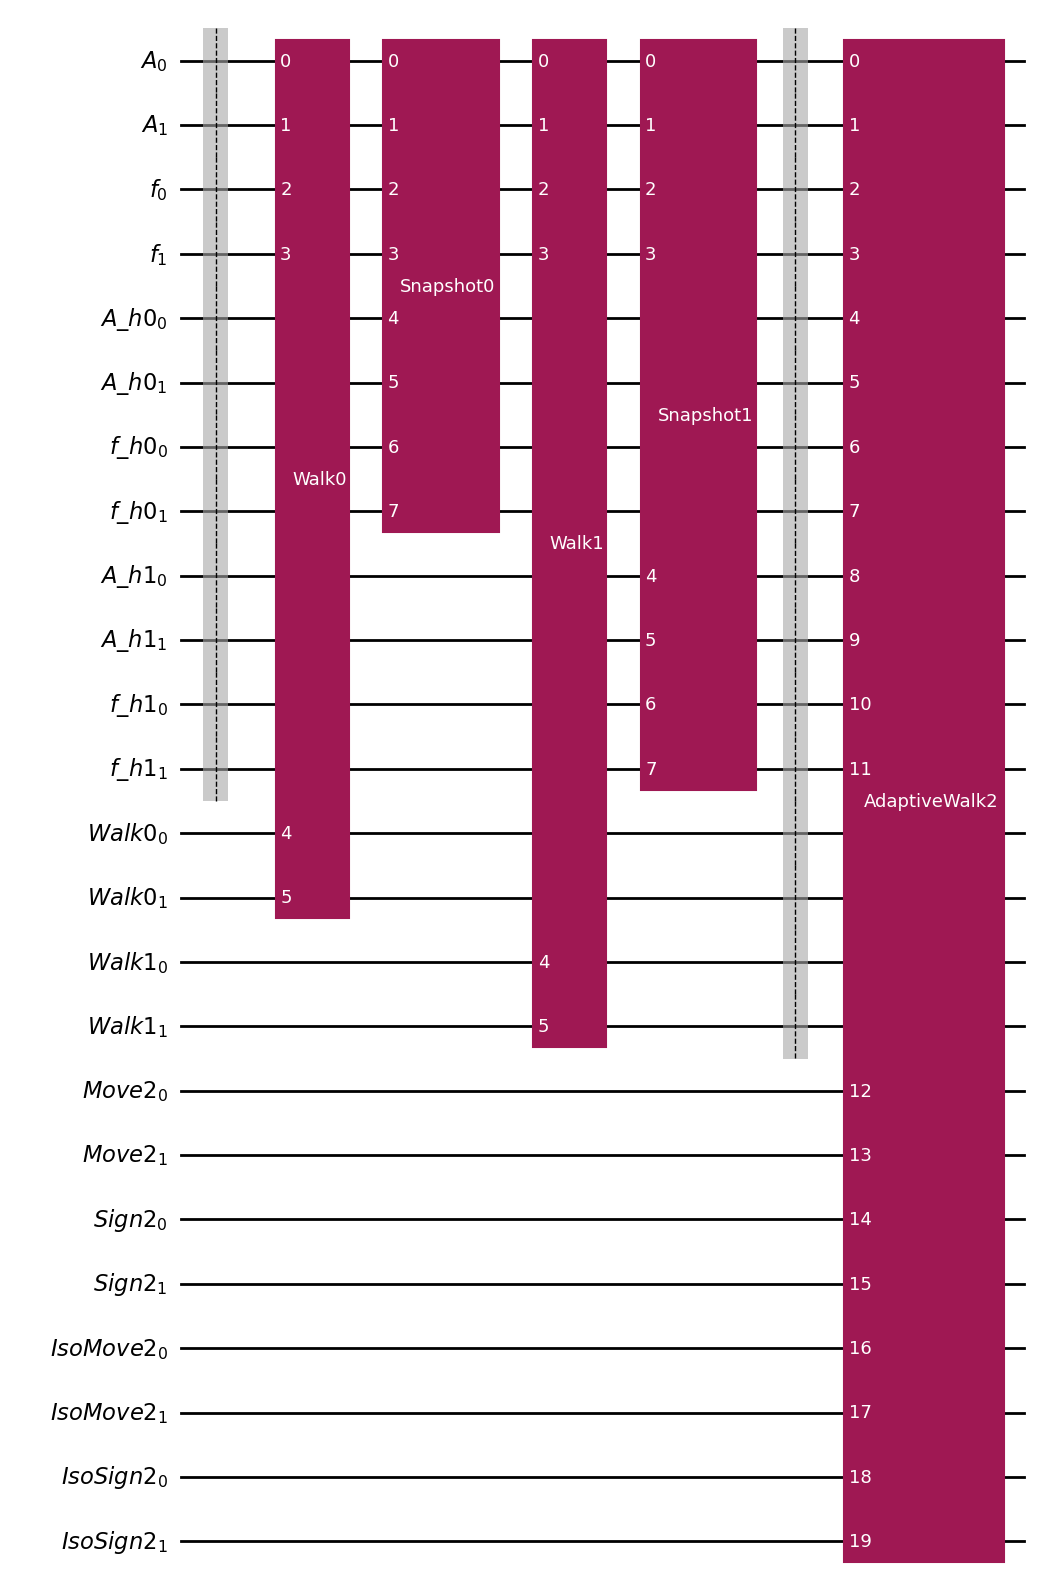

In [10]:
qc_small.draw(output="mpl", fold=-1)

### The full circuit: do step sizes follow the history covariance?

Sample the full circuit, then rebuild each shot's history covariance from its measured history registers.
In every branch the phase-2 displacement must satisfy

$$\mathbb{E}[D D^\top \mid h] = t_2\,(\text{scale2}\cdot S_\text{hist}(h) + \text{iso\_var}\cdot I).$$

The tests below are a z-score per matrix entry, and the slope of observed against predicted for the
diagonal (step size) and off-diagonal (correlation) entries. Both slopes should be 1.

In [11]:
shots = 200_000
b = sample_circuit(qc, shots, seed=5)

Hv = np.stack([regs_values(b, qc, h) for h in regs["H"]], axis=1)       # (shots, K, d)
Dv = regs_values(b, qc, regs["D"], signed=True)                        # unwrapped phase-2 displacement
P_end = regs_values(b, qc, regs["P"])

S_branch = torus_cov(Hv, n_bits_list[0])
pred = t_2 * (scale2 * S_branch + iso_var * np.eye(N_params))          # per-shot conditional covariance
obs = Dv[:, :, None] * Dv[:, None, :]

resid = obs - pred
z = resid.mean(0) / (resid.std(0) / np.sqrt(shots))
print("P_end == last snapshot + D (mod 2^n):", np.all((P_end - Hv[:, -1] - Dv) % resolution_list[0] == 0))
print("scratch register back in |0> in every shot:", np.all(reg_value(b, qc, regs["tmp"]) == 0))
print("mean displacement:", Dv.mean(0).round(3))
print("z-scores of E[D D^T - predicted] (|z| < 3 expected):\n", z.round(2))

iu = np.triu_indices(N_params, 1)
dg = (np.arange(N_params), np.arange(N_params))
def slope(x, y):
    # least-squares slope through the origin; x, y are (shots, entries) and the standard error
    # is clustered by shot, because the entries of one shot share its history and are correlated
    beta = np.sum(x * y) / np.sum(x * x)
    se = np.sqrt(np.sum(np.sum(x * (y - beta * x), axis=1)**2)) / np.sum(x * x)
    return beta, se
x_d, y_d = pred[:, dg[0], dg[1]], obs[:, dg[0], dg[1]]
x_o, y_o = pred[:, iu[0], iu[1]], obs[:, iu[0], iu[1]]
print("\nslope observed/predicted, variances:   %.4f +- %.4f" % slope(x_d, y_d))
print("slope observed/predicted, covariances: %.4f +- %.4f" % slope(x_o, y_o))

print("\nper-step kick std, predicted vs observed (A moved with v=1 in phase 1, the rest with v=2):")
for p, sp, so in zip(params, np.sqrt(pred.mean(0).diagonal() / t_2), Dv.std(0) / np.sqrt(t_2)):
    print(f"  {p:>4s}: {sp:.3f}  {so:.3f}")

P_end == last snapshot + D (mod 2^n): True
scratch register back in |0> in every shot: True
mean displacement: [-0.001  0.014 -0.005  0.001  0.005]
z-scores of E[D D^T - predicted] (|z| < 3 expected):
 [[ 1.72 -0.94 -0.63  0.81  0.84]
 [-0.94  0.85  0.74 -1.25 -0.25]
 [-0.63  0.74  0.99  0.74 -0.47]
 [ 0.81 -1.25  0.74  1.47  1.38]
 [ 0.84 -0.25 -0.47  1.38  1.24]]

slope observed/predicted, variances:   1.0053 +- 0.0034
slope observed/predicted, covariances: 1.0064 +- 0.0045

per-step kick std, predicted vs observed (A moved with v=1 in phase 1, the rest with v=2):
     A: 0.926  0.929
     f: 1.766  1.769
     t: 1.766  1.769
   tau: 1.767  1.772
   phi: 1.766  1.770


The same identity holds on the RW notebook's own 4-point grid, where the history wraps constantly and 11%
of history pairs sit exactly half a grid apart (velocity 1 here, because velocity 2 is degenerate there).

In [12]:
qc4, R4 = build_adaptive_walk(params, [2] * N_params, [1] * N_params, t_1=3, t_2=2,
                              scale2=scale2, iso_var=iso_var, track_displacement=True, e_bits=8)
b4 = sample_circuit(qc4, 200_000, seed=11)
H4 = np.stack([regs_values(b4, qc4, h) for h in R4["H"]], axis=1)
D4 = regs_values(b4, qc4, R4["D"], signed=True)
r4 = D4[:, :, None] * D4[:, None, :] - 2 * (scale2 * torus_cov(H4, 2) + iso_var * np.eye(N_params))
z4 = r4.mean(0) / (r4.std(0) / np.sqrt(len(D4)))
ties = np.mean(((H4[:, :, None, :] - H4[:, None, :, :]) % 4) == 2)
print(f"{qc4.num_qubits} qubits; tie fraction {ties:.3f}; max |z| = {np.abs(z4).max():.2f}; mean D = {D4.mean(0).round(3)}")

129 qubits; tie fraction 0.111; max |z| = 2.41; mean D = [ 0.002 -0.004 -0.001 -0.002 -0.   ]


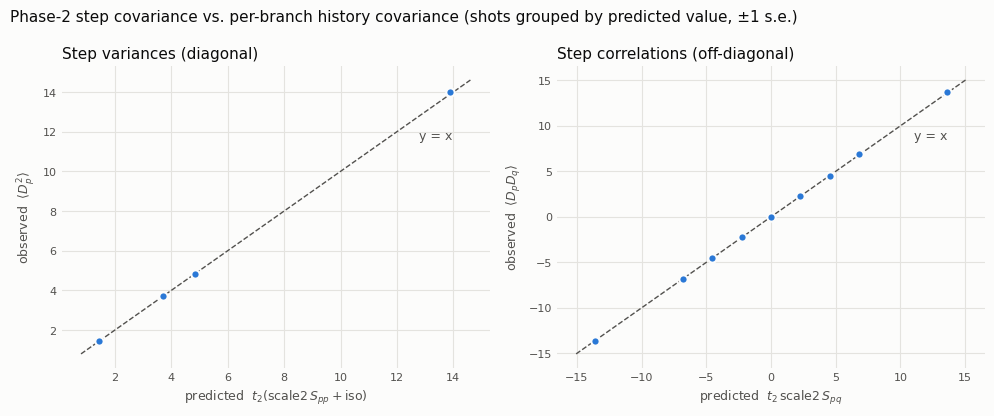

In [13]:
def binned(x, y, min_count=500):
    # predicted values are discrete on the grid: group shots by their predicted value
    keys, inv, counts = np.unique(np.round(x, 9), return_inverse=True, return_counts=True)
    sy = np.bincount(inv, weights=y)
    sy2 = np.bincount(inv, weights=y**2)
    keep = counts >= min_count
    mean = sy[keep] / counts[keep]
    se = np.sqrt(np.maximum(sy2[keep] / counts[keep] - mean**2, 0) / counts[keep])
    return keys[keep], mean, se

ink, muted, grid_c, series = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), facecolor="#fcfcfb")
panels = [
    (x_d, y_d, "Step variances (diagonal)", "predicted  $t_2(\\mathrm{scale2}\\,S_{pp}+\\mathrm{iso})$", "observed  $\\langle D_p^2\\rangle$"),
    (x_o, y_o, "Step correlations (off-diagonal)", "predicted  $t_2\\,\\mathrm{scale2}\\,S_{pq}$", "observed  $\\langle D_p D_q\\rangle$"),
]
for ax, (x, y, title, xl, yl) in zip(axes, panels):
    xs, ys, es = binned(x.ravel(), y.ravel())
    lo, hi = min(xs.min(), ys.min()), max(xs.max(), ys.max())
    pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=muted, lw=1, ls="--", zorder=1)
    ax.text(hi, hi - 3 * pad, "y = x", color=muted, ha="right", va="top", fontsize=9)
    ax.errorbar(xs, ys, yerr=es, fmt="o", ms=6, color=series, ecolor=series, elinewidth=1.5,
                capsize=0, mec="#fcfcfb", mew=1.5, zorder=3)
    ax.set_title(title, color=ink, fontsize=11, loc="left")
    ax.set_xlabel(xl, color=muted, fontsize=9); ax.set_ylabel(yl, color=muted, fontsize=9)
    ax.set_facecolor("#fcfcfb"); ax.grid(color=grid_c, lw=0.8); ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors=muted, labelsize=8, length=0)
fig.suptitle("Phase-2 step covariance vs. per-branch history covariance (shots grouped by predicted value, ±1 s.e.)",
             color=ink, fontsize=11, x=0.01, ha="left")
fig.tight_layout()
plt.show()

### Visualising the walk

The same walk as above, rebuilt with `record_path=True` so that every shot keeps its full path: initial
state, phase-1 history registers, and a record register after each adaptive step. Each panel shows one
parameter's distribution of displacement from the start (minimal image on the 16-point torus) at every
timestep. The dashed line marks the switch from the conventional walk to the covariance-adaptive walk.

In [14]:
qc_path, R_path = build_adaptive_walk(
    params, n_bits_list, velocity_list, t_1, t_2,
    scale2=scale2, iso_var=iso_var, initial_values=initial_values, record_path=True,
)
assert check_coherent(qc_path) > 0
bp = sample_circuit(qc_path, 200_000, seed=21)

G = resolution_list[0]
x0 = np.array(initial_values)
path = np.stack([np.broadcast_to(x0, (bp.shape[1], N_params))]
                + [regs_values(bp, qc_path, h) for h in R_path["H"]]
                + [regs_values(bp, qc_path, r) for r in R_path["R"]], axis=1)      # (shots, time, param)
disp = (path - x0 + G // 2) % G - G // 2                                           # minimal image, -G/2 .. G/2-1
n_t = disp.shape[1]
assert np.all(path[:, -1] == regs_values(bp, qc_path, R_path["P"]))              # last record == final state

# P(displacement | t, parameter)
offsets = np.arange(-G // 2, G // 2)
hist = np.zeros((N_params, G, n_t))
for p in range(N_params):
    for t in range(n_t):
        hist[p, :, t] = np.bincount(disp[:, t, p] + G // 2, minlength=G) / len(disp)

print("std of displacement per timestep (minimal image):")
for p in range(N_params):
    print(f"  {params[p]:>4s}: " + "  ".join(f"{s:4.2f}" for s in disp[:, :, p].std(0)))

std of displacement per timestep (minimal image):
     A: 0.00  1.00  1.42  1.73  1.97  2.17  2.35
     f: 0.00  2.00  2.82  3.47  3.65  3.78  3.88
     t: 0.00  2.00  2.83  3.47  3.65  3.78  3.88
   tau: 0.00  2.00  2.83  3.47  3.64  3.77  3.88
   phi: 0.00  2.00  2.83  3.46  3.65  3.77  3.88


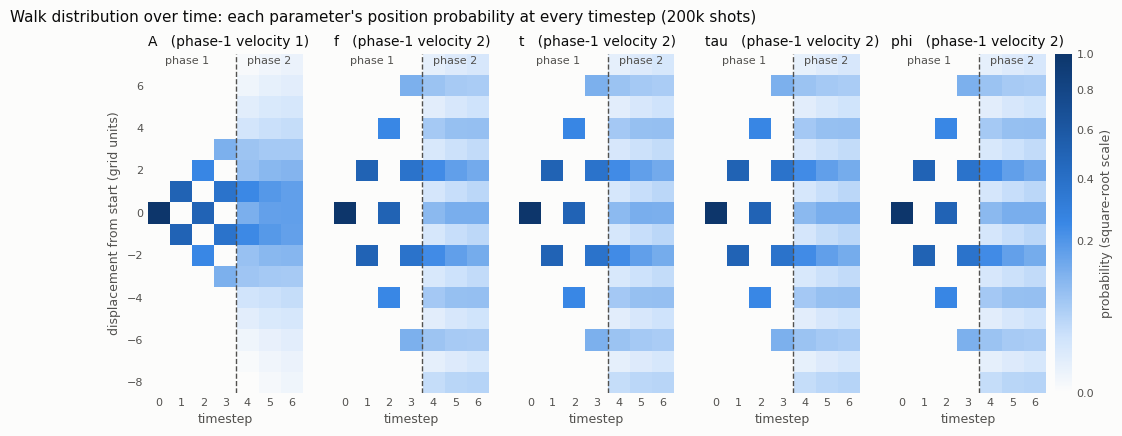

In [15]:
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

surface, ink, muted = "#fcfcfb", "#0b0b0b", "#52514e"
ramp = LinearSegmentedColormap.from_list(
    "seq_blue", [surface, "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
norm = PowerNorm(gamma=0.5, vmin=0, vmax=hist.max())       # square-root scale so the tails stay visible

fig, axes = plt.subplots(1, N_params, figsize=(12, 4.4), sharey=True, facecolor=surface)
for p, ax in enumerate(axes):
    im = ax.imshow(hist[p], origin="lower", aspect="auto", cmap=ramp, norm=norm,
                   extent=(-0.5, n_t - 0.5, offsets[0] - 0.5, offsets[-1] + 0.5), interpolation="nearest")
    ax.axvline(t_1 + 0.5, color=muted, lw=1, ls="--")
    ax.set_title(f"{params[p]}   (phase-1 velocity {velocity_list[p]})", color=ink, fontsize=10, loc="left")
    ax.set_xticks(range(n_t))
    ax.set_xlabel("timestep", color=muted, fontsize=9)
    ax.tick_params(colors=muted, labelsize=8, length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel("displacement from start (grid units)", color=muted, fontsize=9)
for ax in axes:
    ax.text((t_1 - 0.5) / 2, offsets[-1] + 0.4, "phase 1", color=muted, fontsize=8, va="top", ha="center")
    ax.text(t_1 + 0.5 + t_2 / 2, offsets[-1] + 0.4, "phase 2", color=muted, fontsize=8, va="top", ha="center")
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.01)
cb.set_label("probability (square-root scale)", color=muted, fontsize=9)
cb.ax.tick_params(colors=muted, labelsize=8, length=0)
cb.outline.set_visible(False)
fig.suptitle("Walk distribution over time: each parameter's position probability at every timestep (200k shots)",
             color=ink, fontsize=11, x=0.01, ha="left")
plt.show()

## 5. Notes and next steps

* **Cost.** Qubits grow with time: one history register per phase-1 step, plus fresh coins per step
  (`2·K(K−1)/2 + 2·d` per adaptive step). This is the price of "no measurement / no reset". A coin that is
  re-used must be *uncomputed*, which is impossible here, since it is precisely what carries the randomness.
* **Simulation.** The full circuit (~190 qubits) is far beyond statevector memory. The exact sampler is valid
  only because no branch interferes in this circuit class. That holds until a quantum acceptance or
  likelihood step adds interference, after which Aer (or hardware) is required.
* **Fully adaptive (Haario AM).** Snapshotting the state during phase 2 as well (one more history register
  per step) turns the fixed-after-`t_1` covariance into a running one, with no other changes.
* **Parallel tempering.** The gadget is per chain. Instantiate it once per temperature, each with its own
  history, and add the swap move (`cswap` between chain registers, as in `qaptdrjmcmc.ipynb`) after the
  adaptive step. The RW notebook has no acceptance step, so none is added here either.